In [5]:
#!pip install matplotlib
#%matplotlib inline
#!pip install seaborn

In [6]:
from pathlib import Path
try:
    ROOT = Path(__file__).resolve().parent   # script na raiz do projeto
except NameError:
    ROOT = Path.cwd()                        # notebook aberto na raiz do projeto
import numpy as np
import pandas as pd
import sys
import matplotlib
EM_NOTEBOOK = "ipykernel" in sys.modules      # True dentro do Jupyter / VS Code
if EM_NOTEBOOK:
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")   # garante backend que exibe (desfaz um Agg antigo)
else:
    matplotlib.use("Agg")                     # script puro: só grava os PNGs
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
 
SRC = ROOT / "dados" / "gold" / "history_gold.csv"
OUT = ROOT / "graficos"
OUT.mkdir(exist_ok=True)
 
BLUE, RED, GRAY, GREEN, ORANGE = "#4C78A8", "#E45756", "#B0B7C3", "#54A24B", "#F58518"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
 
# ---------------------------------------------------------------- dados
g = pd.read_csv(SRC)
g["Contrato_PT"] = g.Contrato.map({"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"})
g["Internet_PT"] = g.Servico_Internet.map({"Fiber optic": "Fibra", "DSL": "DSL", "No": "Sem internet"})
g["Pagamento_PT"] = g.Metodo_Pagamento.map({
    "Electronic check": "Cheque eletrônico", "Mailed check": "Cheque correio",
    "Bank transfer (automatic)": "Transf. automática", "Credit card (automatic)": "Cartão automático"})
ORD_C = ["Mensal", "1 ano", "2 anos"]
ORD_I = ["Fibra", "DSL", "Sem internet"]
ORD_P = ["Cheque eletrônico", "Cheque correio", "Transf. automática", "Cartão automático"]
ORD_F = ["0-6", "7-12", "13-24", "25-48", "48+"]
MRR = g.Cobranca_Mensal.sum()
net = g[g.Servico_Internet != "No"]
 
 
def br(v, d=0):
    s = f"{v:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")
 
 
def save(fig, name):
    fig.savefig(OUT / name, dpi=150, bbox_inches="tight", facecolor="white")
    if EM_NOTEBOOK:
        plt.show()                            # exibe o gráfico embaixo da célula
    plt.close(fig)

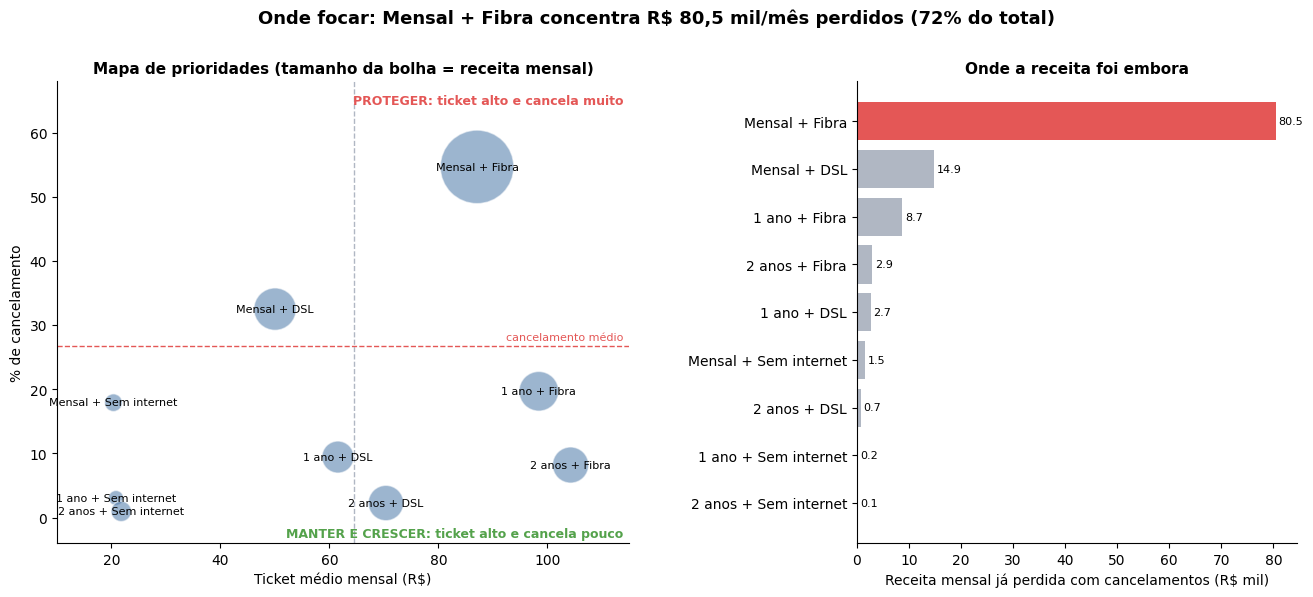

In [14]:
g["Seg9"] = g.Contrato_PT + " + " + g.Internet_PT
sg = g.groupby("Seg9").agg(n=("ID_Cliente", "size"), mrr=("Cobranca_Mensal", "sum"), tk=("Cobranca_Mensal", "mean"),
                           ch=("Cancelou", "mean"))
sg["perdido"] = g[g.Cancelou == 1].groupby("Seg9").Cobranca_Mensal.sum()
sg = sg.fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
ax = axes[0]
ax.scatter(sg.tk, sg.ch * 100, s=sg.mrr / sg.mrr.max() * 2800, color=BLUE, alpha=0.55, edgecolor="white")
for nome, r in sg.iterrows():
    ax.annotate(nome, (r.tk, r.ch * 100), ha="center", va="center", fontsize=8)
ax.axhline(g.Cancelou.mean() * 100, color=RED, ls="--", lw=1)
ax.axvline(g.Cobranca_Mensal.mean(), color=GRAY, ls="--", lw=1)
ax.set_xlim(10, 115)
ax.set_ylim(-4, 68)
ax.text(114, g.Cancelou.mean() * 100 + 1, "cancelamento médio", ha="right", color=RED, fontsize=8)
ax.text(114, 66, "PROTEGER: ticket alto e cancela muito", ha="right", va="top", color=RED, fontsize=9, fontweight="bold")
ax.text(114, -2.5, "MANTER E CRESCER: ticket alto e cancela pouco", ha="right", va="center", color=GREEN, fontsize=9, fontweight="bold")
ax.set_xlabel("Ticket médio mensal (R$)")
ax.set_ylabel("% de cancelamento")
ax.set_title("Mapa de prioridades (tamanho da bolha = receita mensal)")
top = sg.sort_values("perdido")
axes[1].barh(top.index, top.perdido / 1000, color=[RED if v == top.perdido.max() else GRAY for v in top.perdido])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=2, fontsize=8)
axes[1].set_xlabel("Receita mensal já perdida com cancelamentos (R$ mil)")
axes[1].set_title("Onde a receita foi embora")
mp = sg.perdido.idxmax()
fig.suptitle(f"Onde focar: {mp} concentra R$ {br(sg.perdido.max() / 1000, 1)} mil/mês perdidos "
             f"({sg.perdido.max() / sg.perdido.sum() * 100:.0f}% do total)", fontsize=13, fontweight="bold", y=1.0)
save(fig, "08_onde_focar.png")

In [22]:
import matplotlib.pyplot as plt

MOEDA = r"R\$"   # a barra evita que o matplotlib leia o $ como fórmula
BLUE, RED, GRAY, GREEN = "#4C78A8", "#E45756", "#B0B7C3", "#54A24B"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})

# dados 

g = pd.read_csv(ROOT / "dados" / "gold" / "history_gold.csv")
g["Contrato_PT"] = g.Contrato.map({"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"})
g["Internet_PT"] = g.Servico_Internet.map({"Fiber optic": "Fibra", "DSL": "DSL", "No": "Sem internet"})
g["Segmento"] = g.Contrato_PT + " + " + g.Internet_PT
canc = g[g.Cancelou == 1]

total = g.Cobranca_Mensal.sum()
perdida = canc.Cobranca_Mensal.sum()
retida = total - perdida
pct_perdida = perdida / total * 100
FOCO = "Mensal + Fibra"

seg = g.groupby("Segmento").agg(n=("ID_Cliente", "size"), receita=("Cobranca_Mensal", "sum"), churn=("Cancelou", "mean"))
cs = canc.groupby("Segmento").agg(n_canc=("ID_Cliente", "size"), perdida=("Cobranca_Mensal", "sum"), ticket_canc=("Cobranca_Mensal", "mean"))
seg = seg.join(cs).fillna(0)
seg["pct_receita_perdida"] = seg.perdida / seg.receita * 100
seg["custo_anual_cliente"] = seg.ticket_canc * 12


def cores(idx, foco=FOCO):
    return [RED if i == foco else GRAY for i in idx]

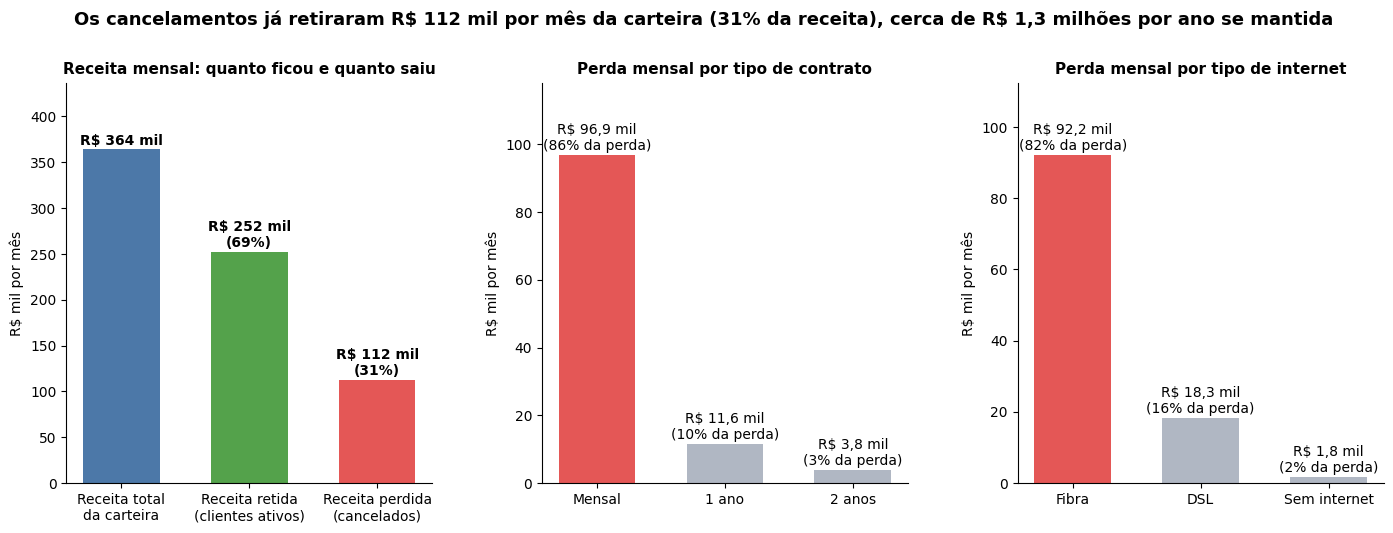

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"wspace": 0.3})

ax = axes[0]
v = [total / 1000, retida / 1000, perdida / 1000]
b = ax.bar(["Receita total\nda carteira", "Receita retida\n(clientes ativos)", "Receita perdida\n(cancelados)"], v,
           color=[BLUE, GREEN, RED], width=0.6)
for rect, val, txt in zip(b, v, ["", f"{retida / total * 100:.0f}%", f"{pct_perdida:.0f}%"]):
    ax.text(rect.get_x() + rect.get_width() / 2, val + total / 1000 * 0.015,
            f"{MOEDA} {br(val)} mil" + (f"\n({txt})" if txt else ""), ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, total / 1000 * 1.2)
ax.set_ylabel(f"{MOEDA} mil por mês")
ax.set_title("Receita mensal: quanto ficou e quanto saiu")

for ax, col, ordem, tit in [(axes[1], "Contrato_PT", ["Mensal", "1 ano", "2 anos"], "Perda mensal por tipo de contrato"),
                            (axes[2], "Internet_PT", ["Fibra", "DSL", "Sem internet"], "Perda mensal por tipo de internet")]:
    t = canc.groupby(col).Cobranca_Mensal.sum().reindex(ordem) / 1000
    b = ax.bar(ordem, t.values, color=[RED if k == t.idxmax() else GRAY for k in ordem], width=0.6)
    for rect, val in zip(b, t.values):
        ax.text(rect.get_x() + rect.get_width() / 2, val + t.max() * 0.015,
                f"{MOEDA} {br(val, 1)} mil\n({val / (perdida / 1000) * 100:.0f}% da perda)", ha="center", fontsize=10)
    ax.set_ylim(0, t.max() * 1.22)
    ax.set_ylabel(f"{MOEDA} mil por mês")
    ax.set_title(tit)

fig.suptitle(f"Os cancelamentos já retiraram {MOEDA} {br(perdida / 1000)} mil por mês da carteira ({pct_perdida:.0f}% da receita), "
             f"cerca de {MOEDA} {br(perdida * 12 / 1e6, 1)} milhões por ano se mantida", fontsize=13, fontweight="bold", y=1.02)
save(fig, "25_impacto_financeiro_perda.png")